# Restauración de fotografías antiguas

Para este miniproyecto enseñamos a una red generativa a convertir una foto dañada (rayones, manchas, ruido, desenfoque, tono sepia, colores lavados) en una foto limpia.

Construimos un **data set personalizado**: escogimos fotos limpias y les aplicamos un envejecimiento sintético escrito por nosotros. Así cada foto limpia tiene su pareja dañada y podemos entrenar de forma supervisada.


## 0. Librerías y configuración

In [ ]:
import os, glob, time, random
import numpy as np
import cv2                              # OpenCV: lo usamos para "envejecer" las fotos
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython import display

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# ---------------- Parámetros principales ----------------
TAM = 256                 # Las imágenes se trabajan a 256x256 (tamaño estándar de Pix2Pix)
MAX_FOTOS = 2000          # Máximo de fotos limpias a usar
VERSIONES_POR_FOTO = 4    # Cada foto limpia genera 4 versiones dañadas distintas (aumenta el data set)
PORC_TEST = 0.10          # 10% de las fotos DE CADA CATEGORÍA se reservan para validación (nunca se entrenan)
COLORIZAR = False         # False: la salida es la foto limpia en blanco y negro (solo se repara el daño)
                          # True : la salida es la foto limpia a color (restaurar + colorizar, más difícil)
BATCH_SIZE = 1            # Como en el artículo de Pix2Pix
LAMBDA = 100              # Peso de la pérdida L1 frente a la pérdida adversaria
PASOS = 20000             # Pasos de entrenamiento (≈ 30–60 min en una T4)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); tf.random.set_seed(SEMILLA)

DIR_DRIVE   = "/content/drive/MyDrive/fotos_restauracion"   # Carpeta del grupo en Drive (personas/casas/perros/gatos)
DIR_LIMPIAS = "/content/fotos_limpias"   # Copia local de las fotos originales
DIR_PARES   = "/content/dataset_pares"   # Aquí se guarda el data set personalizado (dañada | limpia)
os.makedirs(DIR_LIMPIAS, exist_ok=True)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset
Nuestro dataset está en Google Drive, en `Mi unidad/fotos_restauracion/`, con una subcarpeta por categoría:

| Categoría | Fotos |
|---|---|
| personas | 150 |
| casas | 150 |
| perros | 100 |
| gatos | 100 |




In [ ]:
import hashlib, shutil
from google.colab import drive
drive.mount('/content/drive')                      # pide permiso a la cuenta de Google
if os.path.isdir(DIR_DRIVE):
    shutil.copytree(DIR_DRIVE, DIR_LIMPIAS, dirs_exist_ok=True)
else:
    print("No se encontró", DIR_DRIVE, "-> revisen el nombre de la carpeta o agreguen el acceso directo a Mi unidad")

EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
todas = sorted(p for p in glob.glob(DIR_LIMPIAS + '/**/*', recursive=True) if p.lower().endswith(EXT))

# Quitar duplicados exactos (mismo contenido aunque tenga otro nombre)
vistos, rutas = set(), []
for p in todas:
    h = hashlib.md5(open(p, 'rb').read()).hexdigest()
    if h not in vistos:
        vistos.add(h); rutas.append(p)
print(f"Fotos encontradas: {len(todas)} · duplicados quitados: {len(todas) - len(rutas)}")

# ---- Respaldo automático con un data set público ----
if len(rutas) < 50:
    import tensorflow_datasets as tfds
    os.makedirs(DIR_LIMPIAS + '/publico', exist_ok=True)
    try:
        ds_pub = tfds.load('lfw', split='train', as_supervised=True); sacar_img = lambda ej: ej[1]
    except Exception as e:
        ds_pub = tfds.load('tf_flowers', split='train', as_supervised=True); sacar_img = lambda ej: ej[0]
    for i, ej in enumerate(ds_pub.take(MAX_FOTOS)):
        cv2.imwrite(f"{DIR_LIMPIAS}/publico/pub_{i:05d}.jpg", cv2.cvtColor(sacar_img(ej).numpy(), cv2.COLOR_RGB2BGR))
    rutas = sorted(glob.glob(DIR_LIMPIAS + '/publico/*.jpg'))

def categoria(ruta):
    # La categoría es la subcarpeta: .../fotos_limpias/perros/foto.jpg -> "perros"
    rel = os.path.relpath(ruta, DIR_LIMPIAS).split(os.sep)
    return rel[0] if len(rel) > 1 else 'general'

por_categoria = {}
for p in rutas[:MAX_FOTOS]:
    por_categoria.setdefault(categoria(p), []).append(p)
for c, l in por_categoria.items():
    print(f"  {c:10s} {len(l)} fotos")

Mounted at /content/drive
Fotos encontradas: 500 · duplicados quitados: 3
  casas      147 fotos
  gatos      100 fotos
  perros     100 fotos
  personas   150 fotos


## 2. Envejecimiento sintético (el corazón del data set personalizado)
La función `envejecer_foto` simula los daños típicos de una foto antigua. Cada daño se aplica **al azar** y con intensidad aleatoria, por eso dos versiones de la misma foto nunca quedan iguales:

| Daño | Cómo se simula |
|---|---|
| Blanco y negro / sepia | Conversión a gris y luego tinte café |
| Decoloración (foto "lavada") | Bajar contraste y mezclar con un tono amarillento |
| Desenfoque | Filtro gaussiano |
| Grano / ruido | Ruido gaussiano |
| Rayones y dobleces | Líneas y curvas claras u oscuras |
| Manchas y polvo | Círculos difuminados y puntos |
| Viñeteado | Bordes oscurecidos |
| Compresión | Guardar en JPEG de baja calidad |


In [ ]:
def a_gris_3c(img):
    # Convierte a escala de grises pero conserva 3 canales (la red siempre trabaja con RGB)
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)

def envejecer_foto(img):
    # img: arreglo uint8 RGB de TAM x TAM. Devuelve la versión "antigua y dañada"
    h, w = img.shape[:2]
    x = img.astype(np.float32) / 255.0

    # 1) Modo de color: blanco y negro (60%), sepia (25%) o color desteñido (15%)
    r = random.random()
    if r < 0.85:
        x = a_gris_3c((x * 255).astype(np.uint8)).astype(np.float32) / 255.0
        if r >= 0.60:   # tinte sepia
            sepia = np.array([1.07, 0.74, 0.43], np.float32)
            x = np.clip(x * sepia, 0, 1)
    else:              # color desteñido: menos saturación
        gris = a_gris_3c((x * 255).astype(np.uint8)).astype(np.float32) / 255.0
        x = 0.5 * x + 0.5 * gris

    # 2) Decoloración: menos contraste + velo amarillento
    c = random.uniform(0.55, 0.9)
    x = 0.5 + c * (x - 0.5)
    velo = np.array([0.95, 0.88, 0.70], np.float32)
    a = random.uniform(0.0, 0.25)
    x = (1 - a) * x + a * velo

    # 3) Desenfoque
    if random.random() < 0.7:
        k = random.choice([3, 5, 7])
        x = cv2.GaussianBlur(x, (k, k), 0)

    # 4) Grano / ruido
    x = x + np.random.normal(0, random.uniform(0.01, 0.06), (h, w, 1)).astype(np.float32)

    # 5) Rayones y dobleces
    capa = np.zeros((h, w), np.float32)
    signo = lambda: 1 if random.random() < 0.75 else -1      # la mayoría de rayones son claros
    for _ in range(random.randint(2, 12)):
        p1 = (random.randint(0, w), random.randint(0, h))
        if random.random() < 0.6:   # rayón recto y largo
            ang = random.uniform(0, np.pi)
            L = random.randint(30, 250)
            p2 = (int(p1[0] + L * np.cos(ang)), int(p1[1] + L * np.sin(ang)))
            cv2.line(capa, p1, p2, signo() * random.uniform(0.3, 0.8), 1)
        else:                       # rayón curvo suave
            ang = random.uniform(0, 2 * np.pi)
            pts = [p1]
            for _ in range(15):
                ang += random.uniform(-0.3, 0.3)
                pts.append((pts[-1][0] + 6 * np.cos(ang), pts[-1][1] + 6 * np.sin(ang)))
            cv2.polylines(capa, [np.array(pts, np.int32)], False, signo() * random.uniform(0.3, 0.8), 1)
    capa = cv2.GaussianBlur(capa, (3, 3), 0)
    # 6) Manchas (difuminadas, como humedad) y polvo
    manchas = np.zeros((h, w), np.float32)
    for _ in range(random.randint(0, 5)):
        cv2.circle(manchas, (random.randint(0, w), random.randint(0, h)), random.randint(5, 25),
                   random.choice([-1, 1]) * random.uniform(0.1, 0.35), -1)
    capa += cv2.GaussianBlur(manchas, (21, 21), 0)
    for _ in range(random.randint(20, 150)):        # puntos de polvo
        capa[random.randint(0, h - 1), random.randint(0, w - 1)] = random.choice([-1, 1]) * 0.8
    x = x + capa[..., None]

    # 7) Viñeteado (bordes más oscuros)
    if random.random() < 0.6:
        yy, xx = np.mgrid[0:h, 0:w]
        d = np.sqrt(((xx - w / 2) / (w / 2)) ** 2 + ((yy - h / 2) / (h / 2)) ** 2)
        x = x * (1 - random.uniform(0.2, 0.5) * np.clip(d - 0.5, 0, 1))[..., None]

    x = (np.clip(x, 0, 1) * 255).astype(np.uint8)

    # 8) Compresión JPEG de baja calidad
    q = random.randint(25, 70)
    _, buf = cv2.imencode('.jpg', cv2.cvtColor(x, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, q])
    x = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return x

### 2.1 Construir y guardar el data set de pares
Cada par se guarda como **una sola imagen de 256×512**: a la izquierda la foto dañada (entrada) y a la derecha la foto limpia (salida deseada). Es el mismo formato del data set *facades* del tutorial de Pix2Pix de TensorFlow.

La división entrenamiento/prueba se hace **por foto original** y **por categoría** (10 % de personas, 10 % de casas, etc.): la red nunca ve en validación una foto que ya vio entrenando, y la prueba tiene las cuatro categorías en la misma proporción.

In [ ]:
def cargar_limpia(ruta):
    img = cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    m = min(h, w)                                   # recorte cuadrado centrado
    img = img[(h - m) // 2:(h - m) // 2 + m, (w - m) // 2:(w - m) // 2 + m]
    return cv2.resize(img, (TAM, TAM), interpolation=cv2.INTER_AREA)

# División estratificada: 10% de CADA categoría va a prueba
grupos = {'test': [], 'train': []}
for c, lista in por_categoria.items():
    lista = lista[:]; random.shuffle(lista)
    n_test = max(1, round(len(lista) * PORC_TEST))
    grupos['test']  += [(c, p) for p in lista[:n_test]]
    grupos['train'] += [(c, p) for p in lista[n_test:]]

for nombre, lista in grupos.items():
    os.makedirs(f"{DIR_PARES}/{nombre}", exist_ok=True)
    versiones = 1 if nombre == 'test' else VERSIONES_POR_FOTO
    for i, (cat, ruta) in enumerate(lista):
        try:
            limpia = cargar_limpia(ruta)
        except Exception:
            continue                                # se ignora una imagen corrupta
        objetivo = limpia if COLORIZAR else a_gris_3c(limpia)
        for v in range(versiones):
            danada = envejecer_foto(limpia)
            par = np.concatenate([danada, objetivo], axis=1)        # [dañada | limpia]
            # El nombre lleva la categoría: perros_00012_3.jpg
            cv2.imwrite(f"{DIR_PARES}/{nombre}/{cat}_{i:05d}_{v}.jpg",
                        cv2.cvtColor(par, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])

for nombre in grupos:
    print(nombre, "->", len(glob.glob(f"{DIR_PARES}/{nombre}/*.jpg")), "pares")

test -> 50 pares
train -> 1788 pares


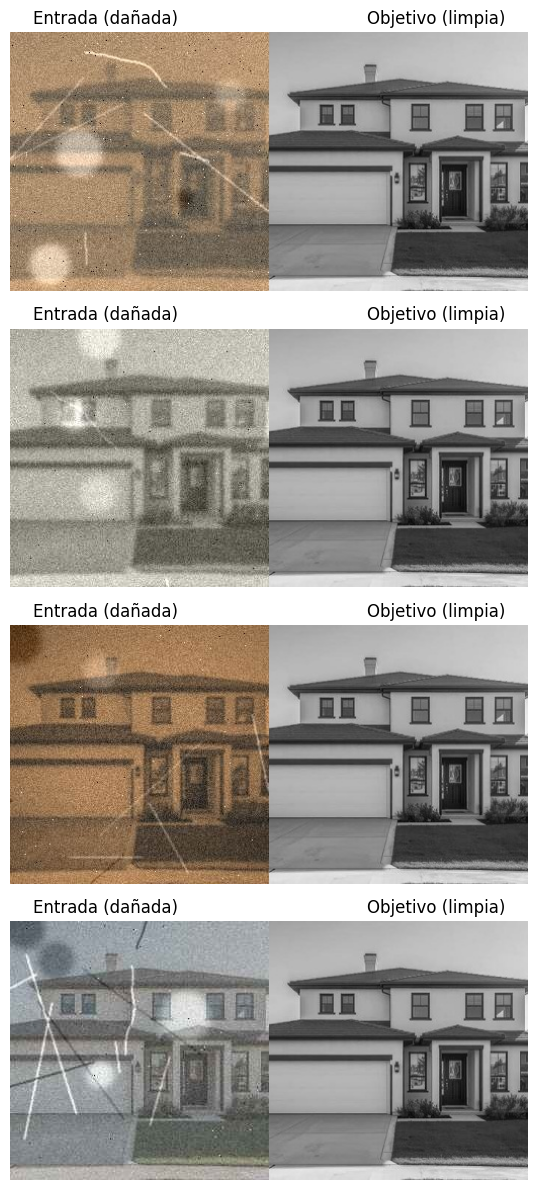

In [ ]:
# Ver algunos ejemplos del data set personalizado
ej = sorted(glob.glob(f"{DIR_PARES}/train/*.jpg"))[:4]
plt.figure(figsize=(12, 12))
for k, r in enumerate(ej):
    plt.subplot(4, 1, k + 1)
    plt.imshow(cv2.cvtColor(cv2.imread(r), cv2.COLOR_BGR2RGB))
    plt.title("Entrada (dañada)                                    Objetivo (limpia)")
    plt.axis('off')
plt.tight_layout(); plt.show()

## 3. Pipeline de datos con `tf.data`
- Se separa cada imagen en (entrada, objetivo).
- Se normalizan los píxeles
- Se agranda a 286×286, se recorta al azar 256×256 y se voltea horizontalmente. Se aplica igual a la entrada y al objetivo para que sigan alineadas. Es aumento de datos para evitar sobreajuste.

In [ ]:
def cargar_par(ruta):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    w = tf.shape(img)[1] // 2
    entrada  = tf.cast(img[:, :w, :], tf.float32)
    objetivo = tf.cast(img[:, w:, :], tf.float32)
    return entrada, objetivo

def normalizar(entrada, objetivo):
    return (entrada / 127.5) - 1, (objetivo / 127.5) - 1      # [0,255] -> [-1,1]

@tf.function
def jitter(entrada, objetivo):
    entrada  = tf.image.resize(entrada,  [286, 286], method='nearest')
    objetivo = tf.image.resize(objetivo, [286, 286], method='nearest')
    apiladas = tf.stack([entrada, objetivo])                    # mismo recorte para las dos
    apiladas = tf.image.random_crop(apiladas, size=[2, TAM, TAM, 3])
    entrada, objetivo = apiladas[0], apiladas[1]
    if tf.random.uniform(()) > 0.5:                              # volteo horizontal
        entrada, objetivo = tf.image.flip_left_right(entrada), tf.image.flip_left_right(objetivo)
    return entrada, objetivo

def prep_train(ruta):
    e, o = cargar_par(ruta); e, o = jitter(e, o); return normalizar(e, o)

def prep_test(ruta):
    return normalizar(*cargar_par(ruta))

train_ds = (tf.data.Dataset.list_files(f"{DIR_PARES}/train/*.jpg", seed=SEMILLA)
            .map(prep_train, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(400).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds = (tf.data.Dataset.list_files(f"{DIR_PARES}/test/*.jpg", shuffle=False)
           .map(prep_test).batch(BATCH_SIZE))

## 4. Arquitectura
### 4.1 Generador: U-Net
- **Codificador**
- **Decodificador**
- **Conexiones de salto
- Última capa con `tanh` → píxeles normalizados.


In [ ]:
INIT = tf.random_normal_initializer(0., 0.02)   # inicialización recomendada en DCGAN / Pix2Pix

def downsample(filtros, tam, batchnorm=True):
    b = tf.keras.Sequential()
    b.add(tf.keras.layers.Conv2D(filtros, tam, strides=2, padding='same',
                                 kernel_initializer=INIT, use_bias=False))
    if batchnorm:
        b.add(tf.keras.layers.BatchNormalization())
    b.add(tf.keras.layers.LeakyReLU())
    return b

def upsample(filtros, tam, dropout=False):
    b = tf.keras.Sequential()
    b.add(tf.keras.layers.Conv2DTranspose(filtros, tam, strides=2, padding='same',
                                          kernel_initializer=INIT, use_bias=False))
    b.add(tf.keras.layers.BatchNormalization())
    if dropout:
        b.add(tf.keras.layers.Dropout(0.5))
    b.add(tf.keras.layers.ReLU())
    return b

def Generador():
    entradas = tf.keras.layers.Input(shape=[TAM, TAM, 3])
    bajada = [
        downsample(64, 4, batchnorm=False),  # (128,128,64)
        downsample(128, 4),                  # (64,64,128)
        downsample(256, 4),                  # (32,32,256)
        downsample(512, 4),                  # (16,16,512)
        downsample(512, 4),                  # (8,8,512)
        downsample(512, 4),                  # (4,4,512)
        downsample(512, 4),                  # (2,2,512)
        downsample(512, 4),                  # (1,1,512)  <- cuello de botella (el "código")
    ]
    subida = [
        upsample(512, 4, dropout=True),      # (2,2,1024)  (512 + 512 del salto)
        upsample(512, 4, dropout=True),      # (4,4,1024)
        upsample(512, 4, dropout=True),      # (8,8,1024)
        upsample(512, 4),                    # (16,16,1024)
        upsample(256, 4),                    # (32,32,512)
        upsample(128, 4),                    # (64,64,256)
        upsample(64, 4),                     # (128,128,128)
    ]
    ultima = tf.keras.layers.Conv2DTranspose(3, 4, strides=2, padding='same',
                                             kernel_initializer=INIT, activation='tanh')  # (256,256,3)
    x = entradas
    saltos = []
    for capa in bajada:
        x = capa(x); saltos.append(x)
    saltos = reversed(saltos[:-1])
    for capa, s in zip(subida, saltos):
        x = capa(x)
        x = tf.keras.layers.Concatenate()([x, s])     # conexión de salto
    return tf.keras.Model(inputs=entradas, outputs=ultima(x), name="Generador_UNet")

generador = Generador()
generador.summary()

Model: "Generador_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 128, 128,  │      3,072 │ input_layer[0][0] │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 64,    │    131,584 │ sequential[0][0]  │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 32, 32,    │    525,312 │ sequential_1[0][… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 16, 16,    │  2,099,200 │ sequential_2[0][… │
│ (Sequential)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 8, 8, 512) │  4,196,352 │ sequential_3[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 4, 4, 512) │  4,196,352 │ sequential_4[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_6        │ (None, 2, 2, 512) │  4,196,352 │ sequential_5[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_7        │ (None, 1, 1, 512) │  4,196,352 │ sequential_6[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_8        │ (None, 2, 2, 512) │  4,196,352 │ sequential_7[0][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 2, 2,      │          0 │ sequential_8[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_9        │ (None, 4, 4, 512) │  8,390,656 │ concatenate[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 4, 4,      │          0 │ sequential_9[0][… │
│ (Concatenate)       │ 1024)             │            │ sequential_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_10       │ (None, 8, 8, 512) │  8,390,656 │ concatenate_1[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 8, 8,      │          0 │ sequential_10[0]… │
│ (Concatenate)       │ 1024)             │            │ sequential_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_11       │ (None, 16, 16,    │  8,390,656 │ concatenate_2[0]… │
│ (Sequential)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 16, 16,    │          0 │ sequential_11[0]

 Total params: 54,425,859 (207.62 MB)

 Trainable params: 54,414,979 (207.58 MB)

 Non-trainable params: 10,880 (42.50 KB)

### 4.2 Discriminador: PatchGAN
En vez de dar **un solo** número "real/falso" para toda la imagen, entrega una **matriz de 30×30**: cada valor dice si un *parche* de ~70×70 píxeles de la imagen se ve real. Esto obliga al generador a cuidar las texturas y detalles locales (justo lo que se pierde en una foto dañada).

Es un discriminador **condicional**, ya que recibe la foto dañada y una foto limpia (real o generada) concatenadas (6 canales).

In [ ]:
def Discriminador():
    entrada  = tf.keras.layers.Input(shape=[TAM, TAM, 3], name='foto_danada')
    objetivo = tf.keras.layers.Input(shape=[TAM, TAM, 3], name='foto_limpia_o_generada')
    x = tf.keras.layers.concatenate([entrada, objetivo])   # (256,256,6)
    x = downsample(64, 4, False)(x)                        # (128,128,64)
    x = downsample(128, 4)(x)                              # (64,64,128)
    x = downsample(256, 4)(x)                              # (32,32,256)
    x = tf.keras.layers.ZeroPadding2D()(x)                 # (34,34,256)
    x = tf.keras.layers.Conv2D(512, 4, strides=1, kernel_initializer=INIT, use_bias=False)(x)  # (31,31,512)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU()(x)
    x = tf.keras.layers.ZeroPadding2D()(x)                 # (33,33,512)
    salida = tf.keras.layers.Conv2D(1, 4, strides=1, kernel_initializer=INIT)(x)  # (30,30,1)
    return tf.keras.Model(inputs=[entrada, objetivo], outputs=salida, name="Discriminador_PatchGAN")

discriminador = Discriminador()
discriminador.summary()

Model: "Discriminador_PatchGAN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ foto_danada         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ foto_limpia_o_gene… │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 256, 256,  │          0 │ foto_danada[0][0… │
│ (Concatenate)       │ 6)                │            │ foto_limpia_o_ge… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_15       │ (None, 128, 128,  │      6,144 │ concatenate_7[0]… │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_16       │ (None, 64, 64,    │    131,584 │ sequential_15[0]… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_17       │ (None, 32, 32,    │    525,312 │ sequential_16[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 34, 34,    │          0 │ sequential_17[0]… │
│ (ZeroPadding2D)     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 31, 31,    │  2,097,152 │ zero_padding2d[0… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 31, 31,    │      2,048 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_11      │ (None, 31, 31,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 33, 33,    │          0 │ leaky_re_lu_11[0… │
│ (ZeroPadding2D)     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 30, 30, 1) │      8,193 │ zero_padding2d_1… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,770,433 (10.57 MB)

 Trainable params: 2,768,641 (10.56 MB)

 Non-trainable params: 1,792 (7.00 KB)

## 5. Funciones de pérdida


In [ ]:
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def perdida_generador(salida_disc_falsa, generada, objetivo):
    adversaria = bce(tf.ones_like(salida_disc_falsa), salida_disc_falsa)
    l1 = tf.reduce_mean(tf.abs(objetivo - generada))
    total = adversaria + LAMBDA * l1
    return total, adversaria, l1

def perdida_discriminador(salida_disc_real, salida_disc_falsa):
    real  = bce(tf.ones_like(salida_disc_real),   salida_disc_real)
    falsa = bce(tf.zeros_like(salida_disc_falsa), salida_disc_falsa)
    return real + falsa

opt_gen  = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)   # valores del artículo Pix2Pix / DCGAN
opt_disc = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

DIR_CKPT = "/content/drive/MyDrive/checkpoints_restauracion"   # en Drive: si Colab se desconecta, no se pierde el avance
ckpt = tf.train.Checkpoint(opt_gen=opt_gen, opt_disc=opt_disc,
                           generador=generador, discriminador=discriminador)
gestor = tf.train.CheckpointManager(ckpt, DIR_CKPT, max_to_keep=2)

## 6. Entrenamiento

In [ ]:
def mostrar(modelo, entrada, objetivo):
    pred = modelo(entrada, training=True)
    plt.figure(figsize=(15, 5))
    for i, (img, t) in enumerate(zip([entrada[0], pred[0], objetivo[0]],
                                     ['Entrada (dañada)', 'Restaurada (red)', 'Objetivo (limpia)'])):
        plt.subplot(1, 3, i + 1); plt.title(t); plt.imshow(img * 0.5 + 0.5); plt.axis('off')
    plt.show()

@tf.function
def paso_entrenamiento(entrada, objetivo):
    with tf.GradientTape() as cinta_g, tf.GradientTape() as cinta_d:
        generada = generador(entrada, training=True)
        d_real  = discriminador([entrada, objetivo], training=True)
        d_falsa = discriminador([entrada, generada], training=True)
        g_total, g_adv, g_l1 = perdida_generador(d_falsa, generada, objetivo)
        d_total = perdida_discriminador(d_real, d_falsa)
    # Cada red actualiza SOLO sus propios pesos con su propia pérdida
    opt_gen.apply_gradients(zip(cinta_g.gradient(g_total, generador.trainable_variables),
                                generador.trainable_variables))
    opt_disc.apply_gradients(zip(cinta_d.gradient(d_total, discriminador.trainable_variables),
                                 discriminador.trainable_variables))
    return g_total, g_adv, g_l1, d_total

historial = {'paso': [], 'g_total': [], 'g_adv': [], 'g_l1': [], 'd_total': []}

def entrenar(pasos):
    ej_entrada, ej_objetivo = next(iter(test_ds.take(1)))
    inicio = time.time()
    for paso, (e, o) in train_ds.repeat().take(pasos).enumerate():
        g_total, g_adv, g_l1, d_total = paso_entrenamiento(e, o)
        if paso % 100 == 0:
            for k, v in zip(['paso', 'g_total', 'g_adv', 'g_l1', 'd_total'],
                            [int(paso), g_total, g_adv, g_l1, d_total]):
                historial[k].append(float(v))
        if (paso + 1) % 1000 == 0:
            display.clear_output(wait=True)
            print(f"Paso {int(paso)+1}/{pasos} · {time.time()-inicio:.0f}s · "
                  f"L_G={float(g_total):.3f} (adv={float(g_adv):.3f}, L1={float(g_l1):.3f}) · L_D={float(d_total):.3f}")
            mostrar(generador, ej_entrada, ej_objetivo)
        if (paso + 1) % 5000 == 0:
            gestor.save()
    gestor.save()

# Si ya existe un checkpoint, se continúa desde ahí
if gestor.latest_checkpoint:
    ckpt.restore(gestor.latest_checkpoint); print("Restaurado:", gestor.latest_checkpoint)

Paso 20000/20000 · 2492s · L_G=16.307 (adv=1.699, L1=0.146) · L_D=0.552


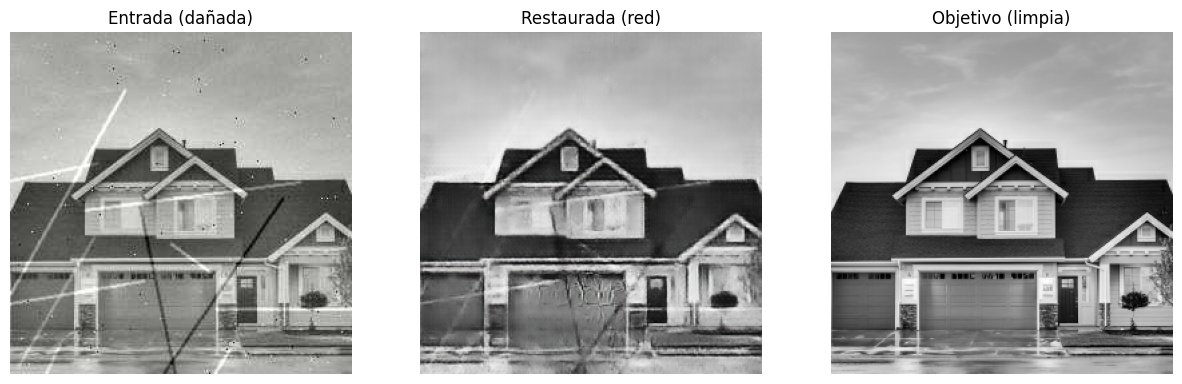

In [ ]:
entrenar(PASOS)

### 6.1 Curvas de pérdida


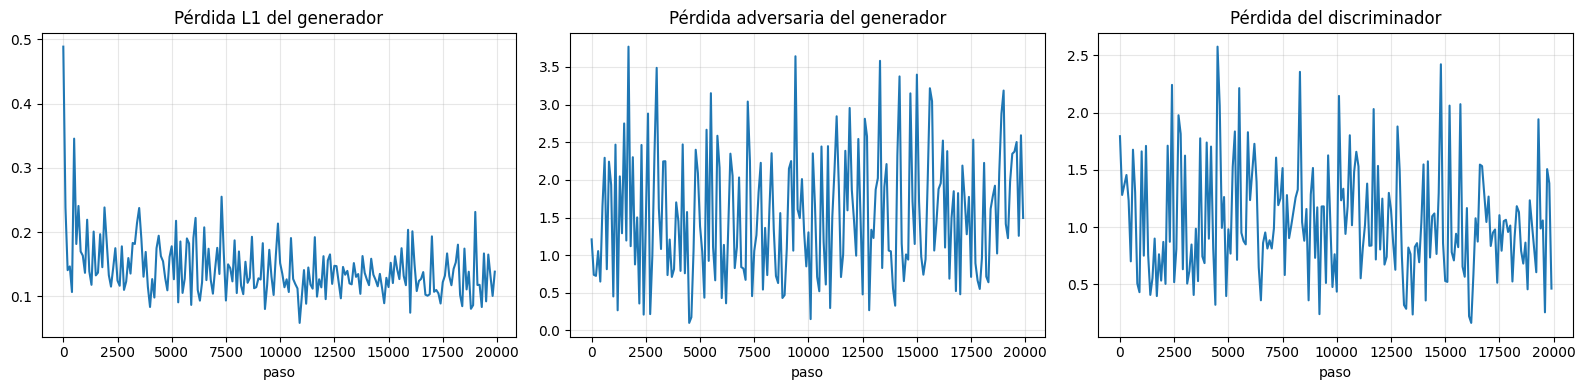

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(historial['paso'], historial['g_l1']);  ax[0].set_title('Pérdida L1 del generador')
ax[1].plot(historial['paso'], historial['g_adv']); ax[1].set_title('Pérdida adversaria del generador')
ax[2].plot(historial['paso'], historial['d_total']); ax[2].set_title('Pérdida del discriminador')
for a in ax: a.set_xlabel('paso'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Validación del modelo


In [ ]:
def a_uint8(t):                       # [-1,1] -> [0,255]
    return tf.cast(tf.clip_by_value((t + 1) * 127.5, 0, 255), tf.uint8)

def metodo_clasico(e_uint8):          # restauración tradicional sin deep learning
    img = e_uint8.numpy()[0]
    img = cv2.medianBlur(img, 5)                       # quita puntos y rayones finos
    img = cv2.bilateralFilter(img, 9, 50, 50)          # suaviza ruido conservando bordes
    if not COLORIZAR:
        img = a_gris_3c(img)
    return tf.constant(img[None])

import pandas as pd
filas = []
for ruta in sorted(glob.glob(f"{DIR_PARES}/test/*.jpg")):
    cat = os.path.basename(ruta).split('_')[0]           # la categoría va en el nombre del archivo
    e, o = prep_test(ruta)
    e, o = e[None], o[None]                              # agregar dimensión de batch
    pred = generador(e, training=True)   # training=True como en Pix2Pix (dropout/batchnorm del artículo)
    o8, e8, p8 = a_uint8(o), a_uint8(e), a_uint8(pred)
    e8_cmp = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(e8)) if not COLORIZAR else e8
    for nombre, img in [('Dañada', e8_cmp), ('Clásico', metodo_clasico(e8)), ('Red (Pix2Pix)', p8)]:
        filas.append(dict(categoria=cat, metodo=nombre,
                          PSNR=float(tf.image.psnr(img, o8, 255)[0]), SSIM=float(tf.image.ssim(img, o8, 255)[0])))
res = pd.DataFrame(filas)
orden = ['Dañada', 'Clásico', 'Red (Pix2Pix)']

print("=== Resultado general (fotos de prueba) ===")
print(res.groupby('metodo')[['PSNR', 'SSIM']].agg(['mean', 'std']).reindex(orden).round(3))
print("\n=== Por categoría ===")
print(res.pivot_table(index='categoria', columns='metodo', values=['PSNR', 'SSIM'], aggfunc='mean')
         .reindex(columns=orden, level=1).round(3))

=== Resultado general (fotos de prueba) ===
                 PSNR          SSIM       
                 mean    std   mean    std
metodo                                    
Dañada         17.514  2.732  0.576  0.106
Clásico        17.330  2.626  0.592  0.124
Red (Pix2Pix)  21.378  2.218  0.660  0.064

=== Por categoría ===
             PSNR                         SSIM                      
metodo     Dañada Clásico Red (Pix2Pix) Dañada Clásico Red (Pix2Pix)
categoria                                                           
casas      17.845  17.441        21.025  0.586   0.563         0.669
gatos      17.044  16.958        21.505  0.584   0.676         0.684
perros     18.164  18.148        22.235  0.593   0.567         0.628
personas   17.063  16.923        21.074  0.549   0.580         0.658


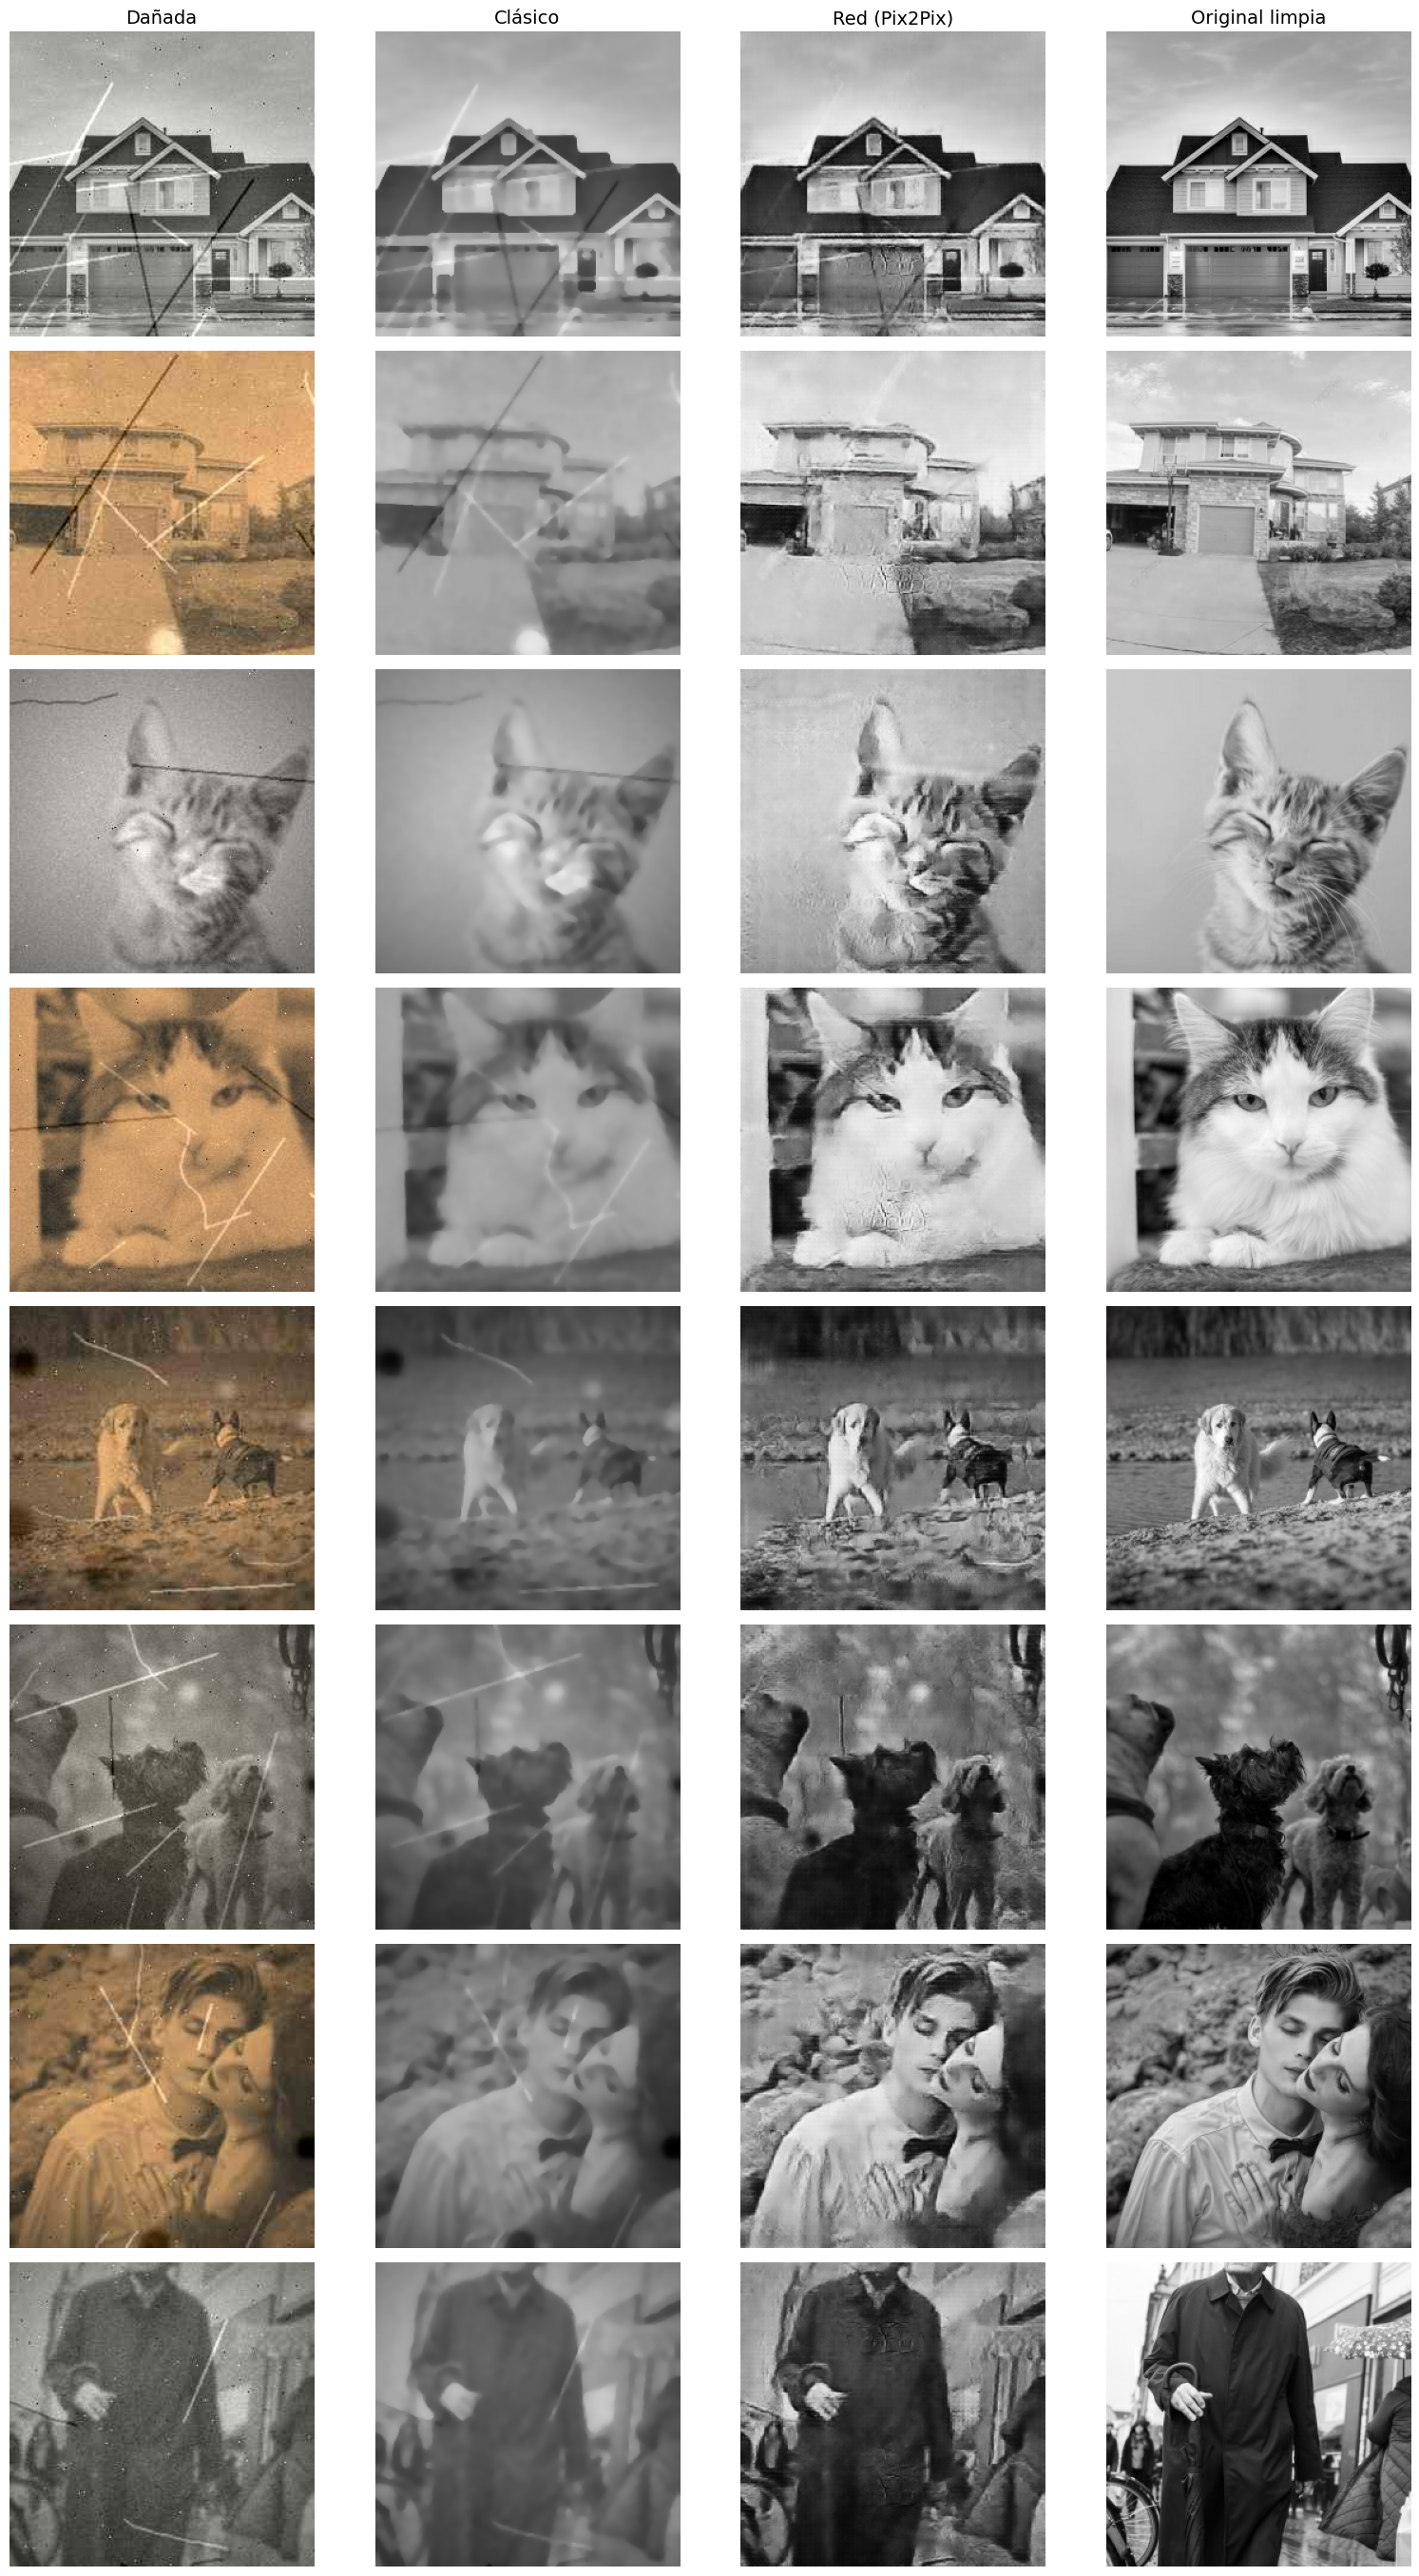

In [ ]:
# Comparación visual: 2 fotos de prueba de cada categoría
test_files = sorted(glob.glob(f"{DIR_PARES}/test/*.jpg"))
cats = sorted({os.path.basename(r).split('_')[0] for r in test_files})
elegidas = [r for c in cats for r in [x for x in test_files if os.path.basename(x).startswith(c + '_')][:2]]
filas = len(elegidas)
plt.figure(figsize=(16, 3.4 * filas))
for i, ruta in enumerate(elegidas):
    e, o = prep_test(ruta); e, o = e[None], o[None]
    pred = generador(e, training=True)
    for j, (img, t) in enumerate([(e[0], 'Dañada'), (tf.cast(metodo_clasico(a_uint8(e))[0], tf.float32) / 127.5 - 1, 'Clásico'),
                                  (pred[0], 'Red (Pix2Pix)'), (o[0], 'Original limpia')]):
        plt.subplot(filas, 4, i * 4 + j + 1)
        plt.imshow(tf.cast(img, tf.float32) * 0.5 + 0.5); plt.axis('off')
        if i == 0: plt.title(t, fontsize=14)
        if j == 0: plt.ylabel(os.path.basename(ruta).split('_')[0])
plt.tight_layout(); plt.show()

## 8. Prueba con fotografías antiguas **reales**


Saving Paris._Rue_Royale._View_from_the_Steps_of_the_Madeleine_WDL1369.png to Paris._Rue_Royale._View_from_the_Steps_of_the_Madeleine_WDL1369.png
Saving Perro viejo 2.jpg to Perro viejo 2.jpg
Saving Perro viejo.jpg to Perro viejo.jpg
Saving Persona.jpg to Persona.jpg
Saving The_American_annual_of_photography_(1911)_(14781068264).jpg to The_American_annual_of_photography_(1911)_(14781068264).jpg


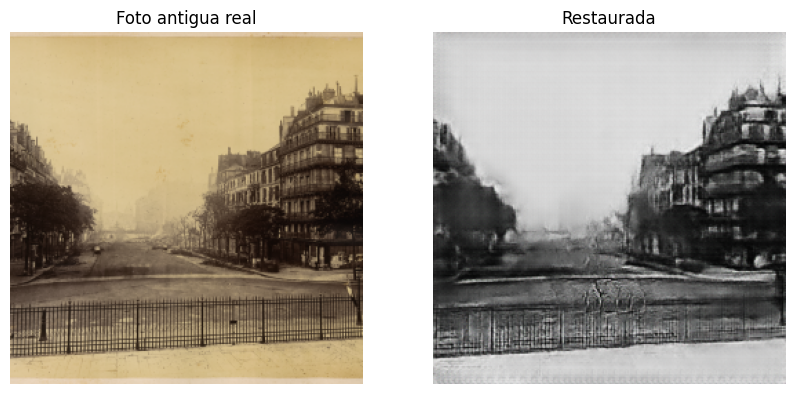

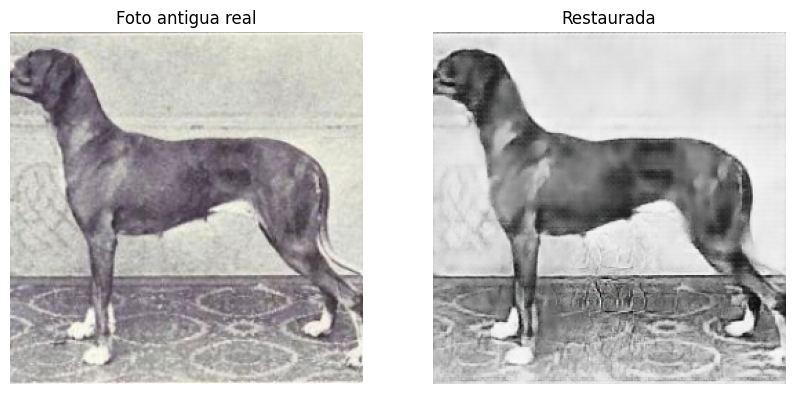

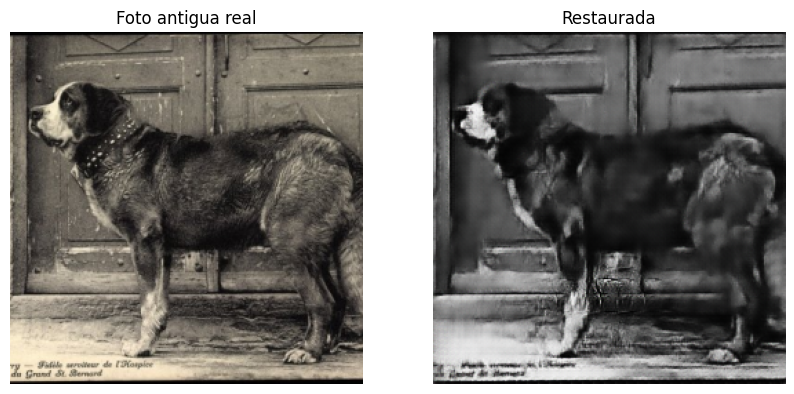

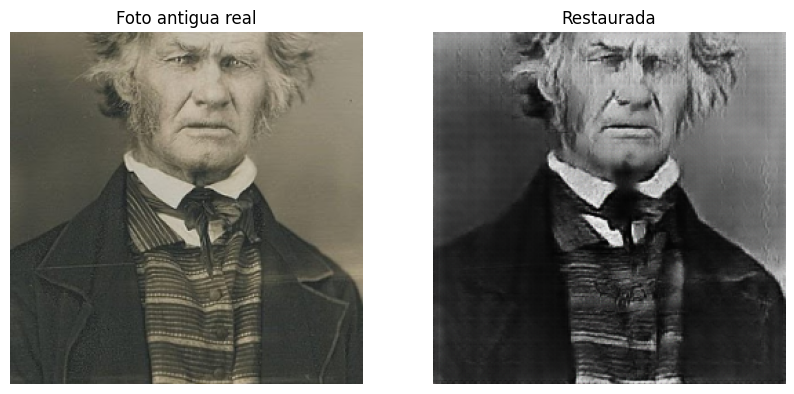

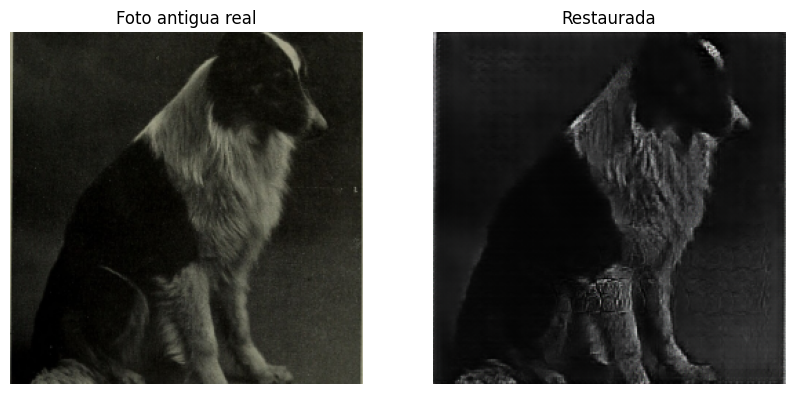

In [ ]:
from google.colab import files
subidas = files.upload()
for nombre in subidas:
    img = cargar_limpia(nombre)                              # recorte cuadrado + 256x256
    x = tf.constant(img[None], tf.float32) / 127.5 - 1
    pred = generador(x, training=True)
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1); plt.imshow(img); plt.title('Foto antigua real'); plt.axis('off')
    plt.subplot(1, 2, 2); plt.imshow(pred[0] * 0.5 + 0.5); plt.title('Restaurada'); plt.axis('off')
    plt.show()

## 9. Guardar el generador entrenado

In [ ]:
generador.save("/content/generador_restauracion.keras")
# from google.colab import files; files.download("/content/generador_restauracion.keras")